# Simulated Data

In [1]:
from STalign import STalign
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import plotly
import requests
import scanpy as sc
import matplotlib
import os

import warnings
warnings.filterwarnings("ignore")

## Load Data

In [2]:
# for loading DLPFC12 data
def load_DLPFC(root_dir='./DLPFC12', section_id='151507'):
    # 151507, ..., 151676
    # 12 in total, 7 layers
    # 151507: n_obs × n_vars = 4221 × 33538
    ad = sc.read_visium(path=os.path.join(root_dir, section_id), count_file=section_id+'_filtered_feature_bc_matrix.h5')
    ad.var_names_make_unique()

    gt_dir = os.path.join(root_dir, section_id, 'gt')
    gt_df = pd.read_csv(os.path.join(gt_dir, 'tissue_positions_list_GTs.txt'), sep=',', header=None, index_col=0)
    ad.obs['original_clusters'] = gt_df.loc[:, 6]
    keep_bcs = ad.obs.dropna().index
    ad = ad[keep_bcs].copy()
    ad.obs['original_clusters'] = ad.obs['original_clusters'].astype(int).astype(str)
    print("spot num", ad)
    return ad


In [3]:
ad = load_DLPFC(root_dir='/pkl_data', section_id='151509')

spot num AnnData object with n_obs × n_vars = 4788 × 33538
    obs: 'in_tissue', 'array_row', 'array_col', 'original_clusters'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial'
    obsm: 'spatial'


In [4]:
ad_target = load_DLPFC(root_dir='/pkl_data', section_id='151510')

spot num AnnData object with n_obs × n_vars = 4595 × 33538
    obs: 'in_tissue', 'array_row', 'array_col', 'original_clusters'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial'
    obsm: 'spatial'


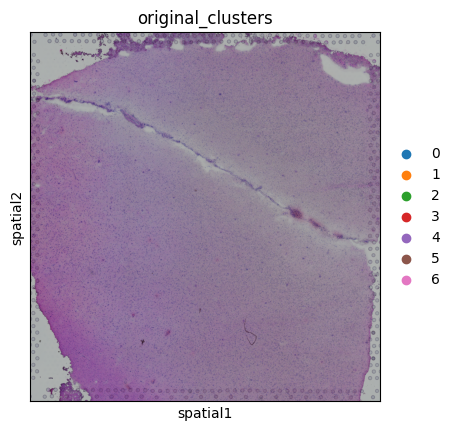

In [5]:
sc.pl.spatial(ad, color='original_clusters', spot_size=1.5)

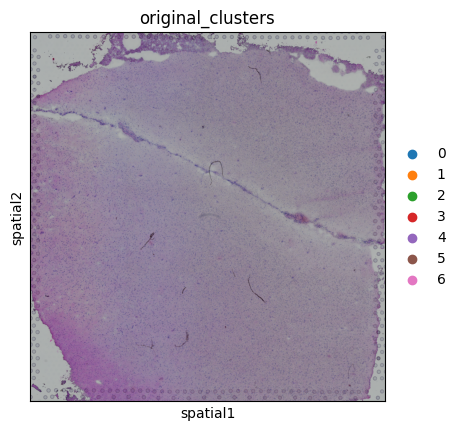

In [6]:
sc.pl.spatial(ad_target, color='original_clusters', spot_size=1.5)

0 of 4595
4594 of 4595


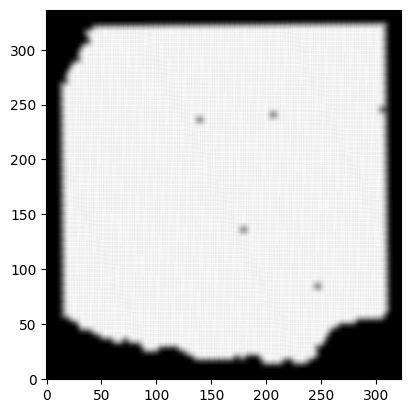

In [7]:
spatial_coords_target = ad_target.obsm['spatial']
x_target = spatial_coords_target[:, 0]
y_target = spatial_coords_target[:, 1]

# fig,ax = plt.subplots()

# rasterize at 30um resolution (assuming positions are in um units) and plot
XJ,YJ,J,fig = STalign.rasterize(x_target,y_target,dx=30,blur=1.5)

# plot
ax = fig.axes[0]
ax.invert_yaxis()

0 of 4788
4787 of 4788


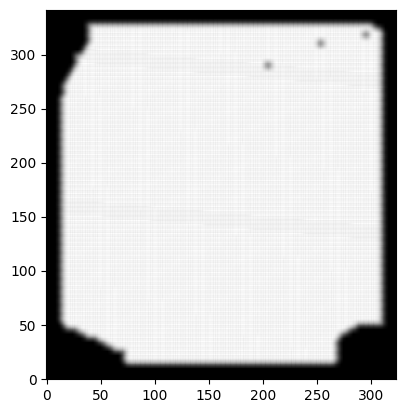

In [8]:
spatial_coords = ad.obsm['spatial']
x = spatial_coords[:, 0]
y = spatial_coords[:, 1]

# fig,ax = plt.subplots()

# rasterize at 30um resolution (assuming positions are in um units) and plot
XI,YI,I,fig = STalign.rasterize(x,y,dx=30,blur=1.5)

# plot
ax = fig.axes[0]
ax.invert_yaxis()

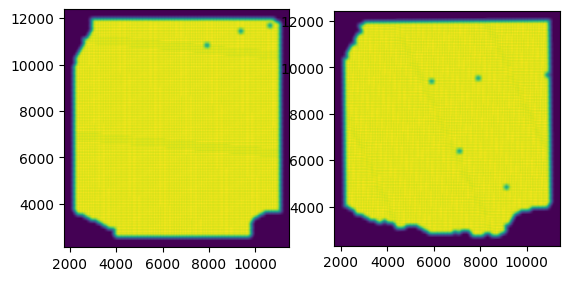

In [9]:
# get extent of images
extentI = STalign.extent_from_x((YI,XI))
extentJ = STalign.extent_from_x((YJ,XJ))

# plot rasterized images
fig,ax = plt.subplots(1,2)
ax[0].imshow(I[0], extent=extentI)
ax[1].imshow(J[0], extent=extentJ)
ax[0].invert_yaxis()
ax[1].invert_yaxis()

CPU times: user 7min 13s, sys: 10 s, total: 7min 23s
Wall time: 6min 35s


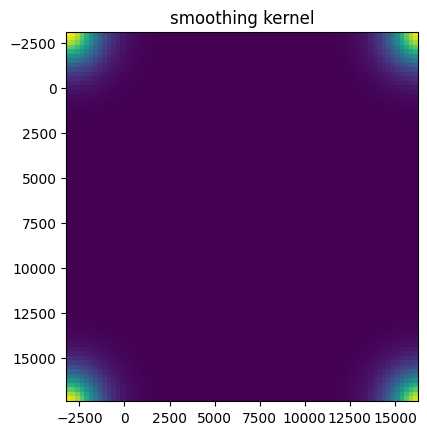

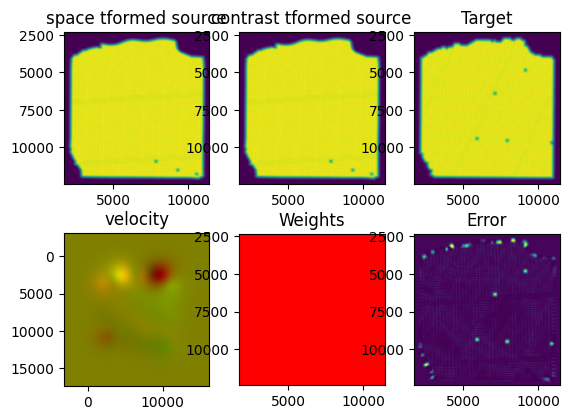

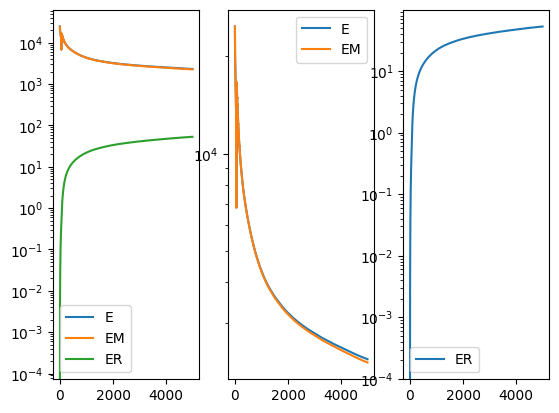

In [10]:
%%time
# run LDDMM
# specify device (default device for STalign.LDDMM is cpu)
if torch.cuda.is_available():
    device = 'cuda:0'
else:
    device = 'cpu'

# keep all other parameters default
params = {
            # 'niter':10000,
            # 'pointsI':pointsI,
            # 'pointsJ':pointsJ,
            # 'L':L,'T':T,
            'niter':5000,
            'device':device,
            'epV': 20,
            'sigmaA': 0.01, #standard deviation of artifact intensities
            'sigmaB': 0.01, #standard deviation of background intensities
            'sigmaM': 0.01, #standard deviation of matching tissue intenities
          }

out = STalign.LDDMM([YI,XI],I,[YJ,XJ],J,**params)

In [11]:
# get necessary output variables
A = out['A']
v = out['v']
xv = out['xv']


In [14]:
pointsI = torch.tensor(np.stack([y, x], 1), device='cuda', dtype=torch.float64)

# apply transform to original points
tpointsI= STalign.transform_points_source_to_target(xv,v,A, pointsI)

#switch tensor from cuda to cpu for plotting with numpy
if tpointsI.is_cuda:
    tpointsI = tpointsI.cpu()

#switch from row column coordinates (y,x) to (x,y)
xI_LDDMM = tpointsI[:,1]
yI_LDDMM = tpointsI[:,0]

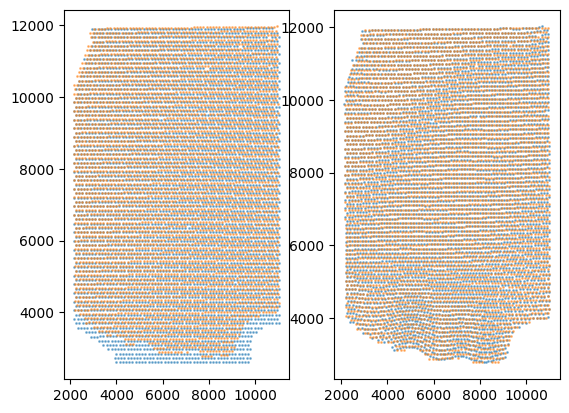

In [15]:
fig,ax = plt.subplots(1,2)
ax[0].scatter(x,y,s=1,alpha=0.5, label='source with initial affine transformation')
ax[0].scatter(x_target,y_target,s=1,alpha=0.5, label='target')
ax[1].scatter(xI_LDDMM,yI_LDDMM,s=1,alpha=0.5, label = 'source STaligned')
ax[1].scatter(x_target,y_target,s=1,alpha=0.5, label='target')
# ax[0].legend(markerscale = 10, loc = 'lower left')
# ax[1].legend(markerscale = 10, loc = 'lower left')

In [16]:
from sklearn.metrics import pairwise

f1 = np.column_stack((x_target, y_target))  # Shape: (n_points, 2)
f2 = np.column_stack((xI_LDDMM, yI_LDDMM))  # Shape: (n_points, 2)
alignment = pairwise.euclidean_distances(f1, f2)
alignment = np.exp(-alignment)

alignment_df = pd.DataFrame(alignment)


In [17]:
# Save as .pkl
alignment_df.to_pickle("151509_151510_AlignmentPi.pkl")

## LAA

In [18]:
# LAA
#calculate laywise bar, result needs to be devided by total number to calculate the accuracy rate
def cal_layer_based_alignment_result(alignment, s1, s2):
    #fei added
    labels = []
    labels.extend(s1.obs['original_clusters'])
    labels.extend(s2.obs['original_clusters'])

    res = []
    l_dict = {"0": 0, "1": 1, "2": 2, "3": 3, "4": 4, "5": 5, "6": 6}
    cnt0 = 0
    cnt1 = 0
    cnt2 = 0
    cnt3 = 0
    cnt4 = 0
    cnt5 = 0
    cnt6 = 0
    for i, elem in enumerate(alignment):
        if np.max(elem) - np.min(elem) != 0: # paste2 might have spots that are not aligned to any other spots. paste might have negative alignment
            if labels[i] == '-1' or labels[elem.argmax() + alignment.shape[0]] == '-1':
                continue
            if l_dict[labels[i]] == l_dict[labels[elem.argmax() + alignment.shape[0]]]:
                cnt0 += 1
            if abs(l_dict[labels[i]] - l_dict[labels[elem.argmax() + alignment.shape[0]]]) == 1:
                cnt1 += 1
            if abs(l_dict[labels[i]] - l_dict[labels[elem.argmax() + alignment.shape[0]]]) == 2:
                cnt2 += 1
            if abs(l_dict[labels[i]] - l_dict[labels[elem.argmax() + alignment.shape[0]]]) == 3:
                cnt3 += 1
            if abs(l_dict[labels[i]] - l_dict[labels[elem.argmax() + alignment.shape[0]]]) == 4:
                cnt4 += 1
            if abs(l_dict[labels[i]] - l_dict[labels[elem.argmax() + alignment.shape[0]]]) == 5:
                cnt5 += 1
            if abs(l_dict[labels[i]] - l_dict[labels[elem.argmax() + alignment.shape[0]]]) == 6:
                cnt6 += 1
    res.extend([cnt0, cnt1, cnt2, cnt3, cnt4, cnt5, cnt6])
    return res

In [19]:
res = cal_layer_based_alignment_result(alignment, ad, ad_target)
res

[1161, 1180, 1377, 518, 218, 126, 15]

In [20]:
divisor = alignment.shape[0]
LAA_result = [num / divisor for num in res]
print(LAA_result)

[0.2526659412404788, 0.25680087051142547, 0.29967355821545155, 0.11273122959738846, 0.04744287268770402, 0.027421109902067465, 0.003264417845484222]


In [83]:
alignment.shape

(3611, 3596)

## ARI

In [21]:
from sklearn.metrics import adjusted_rand_score


def compute_alignment_ari(sliceA, sliceB, pi):
    mapped_clusters = []
    for j in range(pi.shape[1]):
        mapping = pi[:, j]
        #original: if np.sum(mapping) > 0:
        if np.max(mapping) - np.min(mapping) != 0:
            i = np.argmax(mapping)
            mapped_clusters.append(sliceA.obs['original_clusters'][i])
        else:
            mapped_clusters.append("NULL")
    assert len(sliceB.obs['original_clusters']) == len(mapped_clusters)
    true_clusters_mapped_region = []
    mapped_clusters_mapped_region = []
    for i in range(len(sliceB.obs['original_clusters'])):
        if mapped_clusters[i] != "NULL":
            true_clusters_mapped_region.append(sliceB.obs['original_clusters'][i])
            mapped_clusters_mapped_region.append(mapped_clusters[i])

    ari = adjusted_rand_score(true_clusters_mapped_region, mapped_clusters_mapped_region)
    return ari

In [22]:
ari = compute_alignment_ari(ad_target, ad, alignment)
ari

0.6855998913570792

## 3D

In [23]:
dfs = ad.obs['original_clusters']
df1 = dfs.reset_index()
df1.head()

,index,original_clusters
0,AAACAAGTATCTCCCA-1,1
1,AAACAATCTACTAGCA-1,3
2,AAACACCAATAACTGC-1,6
3,AAACAGAGCGACTCCT-1,3
4,AAACAGCTTTCAGAAG-1,4


In [24]:
df3_1 = pd.DataFrame(
    {
        "X": xI_LDDMM,
        "Y": yI_LDDMM,
    },
)

results1 = pd.concat([df1, df3_1], axis=1)
results1['Z'] = 2
results1['slice'] = '151509'
results1

,index,original_clusters,X,Y,Z,slice
0,AAACAAGTATCTCCCA-1,1,9234.086036,8812.499160,2,151509
1,AAACAATCTACTAGCA-1,3,5329.100790,3517.761558,2,151509
2,AAACACCAATAACTGC-1,6,3478.970070,9742.166940,2,151509
3,AAACAGAGCGACTCCT-1,3,8536.340432,4542.984068,2,151509
4,AAACAGCTTTCAGAAG-1,4,2802.162396,7839.663172,2,151509
...,...,...,...,...,...,...
4783,TTGTTTCACATCCAGG-1,4,5077.032980,9667.605607,2,151509
4784,TTGTTTCATTAGTCTA-1,5,4247.775465,9871.931045,2,151509
4785,TTGTTTCCATACAACT-1,4,4047.921827,8124.668638,2,151509
4786,TTGTTTGTATTACACG-1,6,4992.151747,11435.345114,2,151509


In [25]:
results1.to_csv("151509.csv", index=False)

In [26]:
dfs = ad_target.obs['original_clusters']
df0 = dfs.reset_index()
# df0.head()

df3_0 = pd.DataFrame(
    {
        "X": x_target,
        "Y": y_target,
    },
)

results = pd.concat([df0, df3_0], axis=1)
results['Z'] = 3
results['slice'] = '151510'
results

,index,original_clusters,X,Y,Z,slice
0,AAACAAGTATCTCCCA-1,1,9235,8703,3,151510
1,AAACACCAATAACTGC-1,5,3483,9743,3,151510
2,AAACAGAGCGACTCCT-1,3,8714,4364,3,151510
3,AAACAGCTTTCAGAAG-1,4,2805,7811,3,151510
4,AAACAGGGTCTATATT-1,4,3079,8295,3,151510
...,...,...,...,...,...,...
4590,TTGTTTCACATCCAGG-1,4,5075,9635,3,151510
4591,TTGTTTCATTAGTCTA-1,5,4243,9870,3,151510
4592,TTGTTTCCATACAACT-1,3,4049,8062,3,151510
4593,TTGTTTGTATTACACG-1,6,4993,11441,3,151510


In [27]:
results.to_csv("151510.csv", index=False)

## Plot 3D

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import os
import numpy as np

In [6]:
folder_path = './'

# List all CSV files in the folder
csv_files = [file for file in os.listdir(folder_path) if file.endswith('.csv')]
# csv_files
csv_files.sort(key=lambda x: int(''.join(filter(str.isdigit, x))))

# Read and combine all CSV files
combined_df = pd.concat([pd.read_csv(os.path.join(folder_path, file)) for file in csv_files])

# Display the combined DataFrame
combined_df

,index,original_clusters,X,Y,Z,slice
0,AAACAACGAATAGTTC-1,1,3539.208441,2601.217391,0,151507
1,AAACAAGTATCTCCCA-1,3,9223.114783,8902.627509,0,151507
2,AAACAATCTACTAGCA-1,1,5224.268403,2964.131248,0,151507
3,AAACACCAATAACTGC-1,0,3465.097650,10018.593526,0,151507
4,AAACAGCTTTCAGAAG-1,6,2767.470421,7942.763649,0,151507
...,...,...,...,...,...,...
4590,TTGTTTCACATCCAGG-1,4,5075.000000,9635.000000,3,151510
4591,TTGTTTCATTAGTCTA-1,5,4243.000000,9870.000000,3,151510
4592,TTGTTTCCATACAACT-1,3,4049.000000,8062.000000,3,151510
4593,TTGTTTGTATTACACG-1,6,4993.000000,11441.000000,3,151510


In [11]:
# Combine unique clusters from all slices
unique_clusters = combined_df['original_clusters'].unique()
sorted_clusters = np.sort(unique_clusters)

cmap = []
if len(sorted_clusters) <= 10: # when no. of layers <=10
    for e in plt.get_cmap('tab10').colors:
        cmap.append(matplotlib.colors.rgb2hex(e))
else: # when 10< no. of layers <=60
    colormaps = ['tab20', 'tab20b', 'tab20c']
    for cmap_name in colormaps:
        for color in plt.get_cmap(cmap_name).colors:
            cmap.append(matplotlib.colors.rgb2hex(color))

# Create the dictionary with the combined clusters
c_dict = dict(zip(sorted_clusters, cmap))
c_dict

{0: '#1f77b4',
 1: '#ff7f0e',
 2: '#2ca02c',
 3: '#d62728',
 4: '#9467bd',
 5: '#8c564b',
 6: '#e377c2'}

In [14]:
combined_df['celltype_colors'] = combined_df['original_clusters'].replace(c_dict)
combined_df.to_csv('STalign_DLPFC_151509_151510_aligned_coordinates_colors.csv', index=False)

In [15]:
def plot_3d(
    loc,
    val=None,
    color=None,
    figsize=(8,8),
    return_fig=True,
    elev=None,
    azim=None,
    xlim=None,
    ylim=None,
    zlim=None,
    frameon=True,
    save_path=None,
    save_dpi=150,
    show=True,
    *args,
    **kwargs
):
    """Plot all slices stacked in 3D

    Plot all slices stacked with a given number of subplots rows and columns. Spots/cells colored by spatial domain.

    Args:
        loc: An array of the coordinates of each spots/cells in all slices, which the first three columns are X-axis, Y-axis, Z-axis coordinates.
        val: The colors of each spots/cells given in loc use to plot.
        color: The colors of each spots/cells given in loc use to plot.
        figsize: Size of the figure.
        return_fig: Whether to return the figure.
        elev: The elevation angle in the vertical plane in degrees. If ``None`` then the initial value as specified in the ``Axes3D`` constructor is used.
        azim: The azimuth angle in the horizontal plane in degrees. If ``None`` then the initial value as specified in the ``Axes3D`` constructor is used.
        xlim: A tuple given the left and right xlims in X-axis.
        ylim: A tuple given the left and right xlims in Y-axis.
        zlim: A tuple given the left and right xlims in Z-axis.
        frameon: Whether to hide the coordinate axes.
        save_path: A string representing the path directory where the figure saved.
        save_dpi: The resolution in dots per inch.
        show: Whether to show the figure.

    Returns:
        A ``matplotlib.figure.Figure`` object
    """
    if 'marker' not in kwargs.keys():
        kwargs['marker'] = 'o'
    if 's' not in kwargs.keys():
        kwargs['s'] = 5
    if 'cmap' not in kwargs.keys():
        kwargs['cmap'] = 'Spectral_r'
    fig = plt.figure(figsize=figsize)
    ax = fig.add_subplot(projection='3d')
    if (elev is not None) and (azim is not None):
        ax.view_init(elev, azim)
    if color is None:
        ax.scatter(loc[:,0], loc[:,1], loc[:,2],c=val,*args,**kwargs)
    else:
        ax.scatter(loc[:,0], loc[:,1], loc[:,2],c=color,*args,**kwargs)
    if xlim is not None:
        ax.set_xlim(xlim)
    if ylim is not None:
        ax.set_ylim(ylim)
    if zlim is not None:
        ax.set_zlim(zlim)
    # ax.set_aspect('equal')
    if not frameon:
        plt.axis('off')
        plt.grid(b=None)
    if save_path is not None:
        print(save_path)
        plt.savefig(save_path,dpi=save_dpi,bbox_inches='tight')
    if show:
        plt.show()
    else:
        plt.close()
    if return_fig:
        return fig

C:\Users\Lucif\AppData\Local\Temp\ipykernel_24616\949103768.py:55: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(loc[:,0], loc[:,1], loc[:,2],c=color,*args,**kwargs)
C:\Users\Lucif\AppData\Local\Temp\ipykernel_24616\949103768.py:55: MatplotlibDeprecationWarning: The clean function was deprecated in Matplotlib 3.8 and will be removed in 3.10. Use none, you no longer need to clean a Grouper instead.
  ax.scatter(loc[:,0], loc[:,1], loc[:,2],c=color,*args,**kwargs)


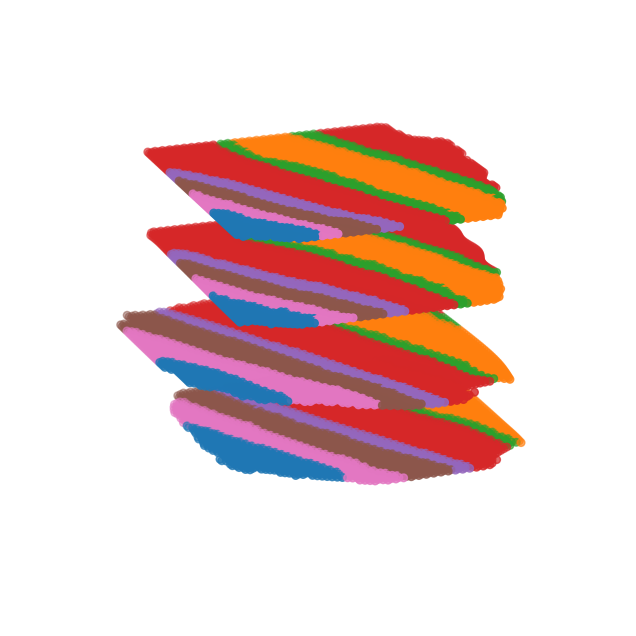

In [16]:
coords = combined_df[['X', 'Y', 'Z']]

fig = plot_3d(coords.values, val=None, color=combined_df['celltype_colors'], elev=20, azim=160, frameon=False, show=True, s=30, return_fig=True) # Scube is from SPACEL

fig.savefig('STalign_gtAndScube_DLPFC_151507_151510_3dviz_angle20_160_s=30.pdf', bbox_inches="tight")